
# Module 13.2 — Sentiment Analysis: Complete Notes 🧠

## 1. Definition and importance

Sentiment analysis is an NLP task that identifies and categorizes opinions, attitudes and sentiment expressed in text.


### Why is it important?

- Customer feedback: Understand satisfaction and complaints.
- Social media monitoring: Track public opinions about brands and products.
- Product reviews: Identify strengths and weaknesses.
- Market research: Understand customer preferences and changing trends.
- Customer support: Automatically categorize feedback for prioritization.
- Business decisions: Use customer opinions to guide product improvements.

Example:

> “The laptop is fast, but its battery life is disappointing.”

A basic sentiment classifier might assign an overall negative or mixed sentiment. An aspect-based system could identify positive sentiment toward performance and negative sentiment toward battery life.

That distinction is important: sentiment can target an entire document or a specific aspect of a product.

## 2. Types of sentiment analysis

Your video covers several types beyond positive, negative and neutral classification. These describe what the system analyzes and at what level of detail.

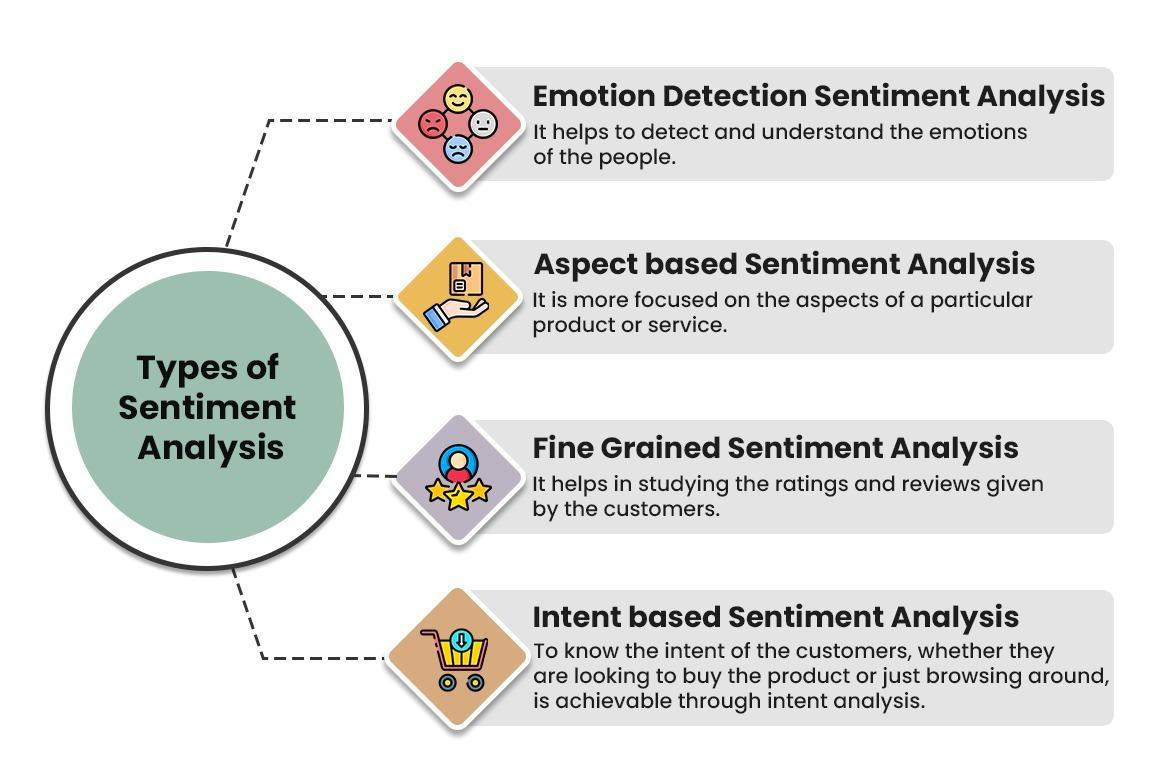

### 2.1 Subjective vs. objective analysis

- Subjectivity detection: Determines whether text expresses an opinion or personal judgment.
- Objective text detection: Identifies factual or descriptive statements without an obvious opinion.

Examples:

| Text                              | Likely interpretation |
| --------------------------------- | --------------------- |
| “This phone is beautiful.”        | Subjective            |
| “The phone weighs 180 grams.”     | Objective             |
| “I think this is the best phone.” | Subjective            |

Important: Subjectivity and sentiment polarity are different. A subjective statement can be positive, negative or neutral.

### 2.2 Fine-grained sentiment analysis

Instead of only three classes, sentiment can be classified into more detailed categories.

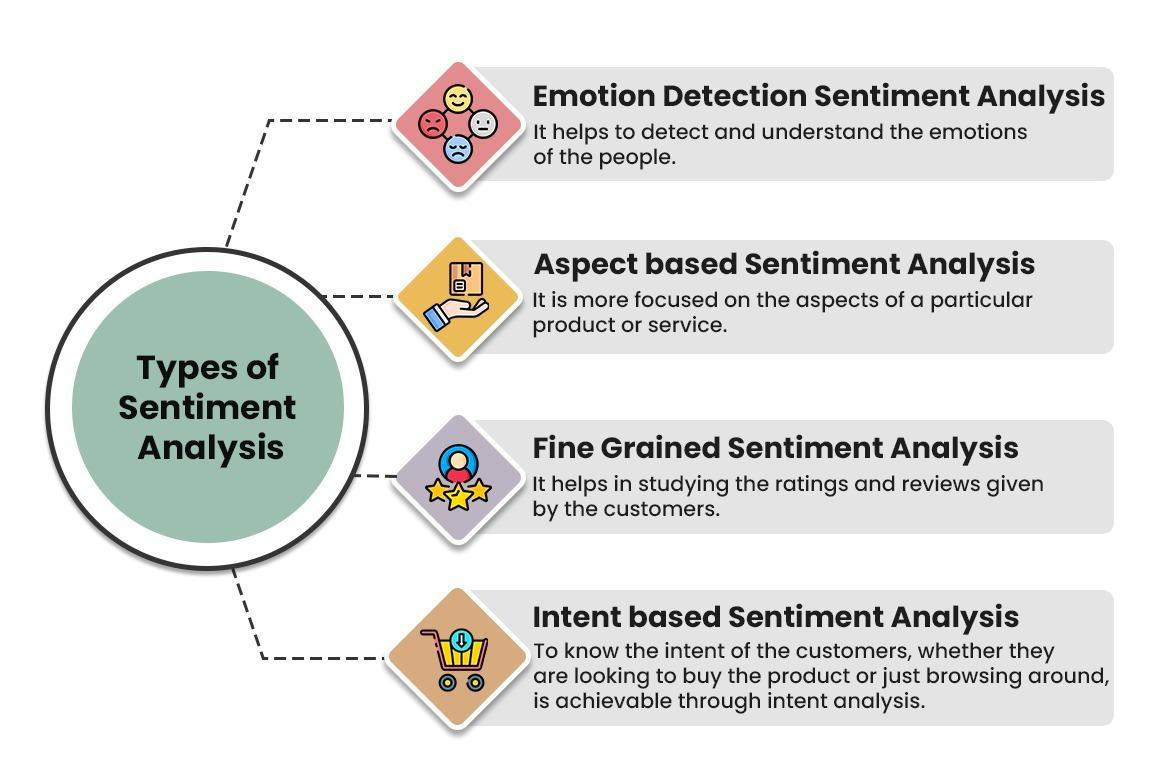


For example:

| Rating  | Sentiment     |
| ------- | ------------- |
| 1 star  | Very negative |
| 2 stars | Negative      |
| 3 stars | Neutral       |
| 4 stars | Positive      |
| 5 stars | Very positive |

This is useful when analyzing product ratings, customer satisfaction and review trends. The labels and rating thresholds depend on the dataset.

### 2.3 Emotion detection

Emotion detection predicts a more specific emotion instead of only positive or negative polarity.

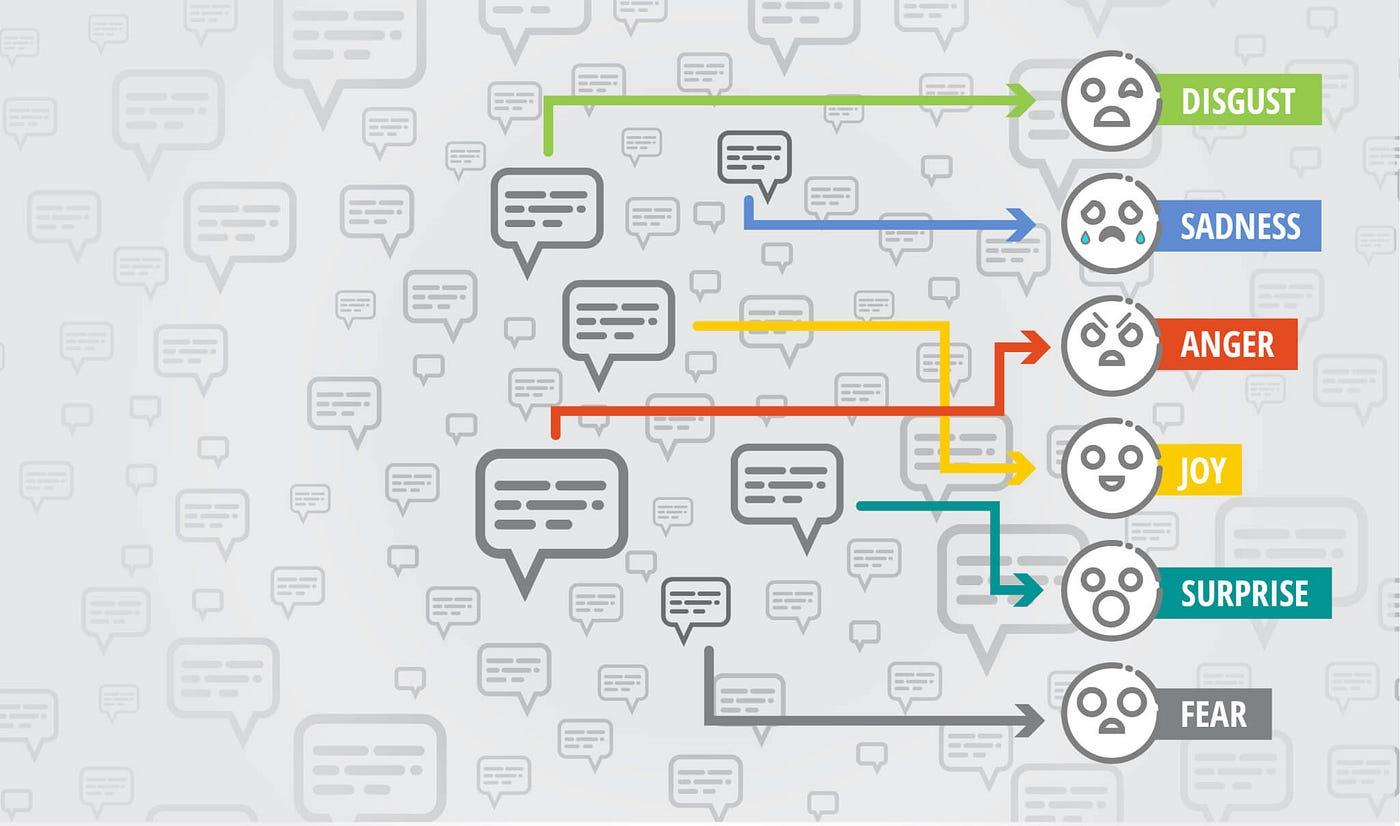

Common categories include:

- Joy
- Sadness
- Anger
- Fear
- Surprise
- Disgust

Example: “I am terrified about tomorrow's interview.”

The text may express fear or anxiety. Emotion detection and sentiment analysis overlap, but they are not identical: fear is an emotion, whereas negative is a sentiment polarity.

### 2.4 Aspect-based sentiment analysis (ABSA)

ABSA identifies sentiment toward specific features of a product, service or topic.


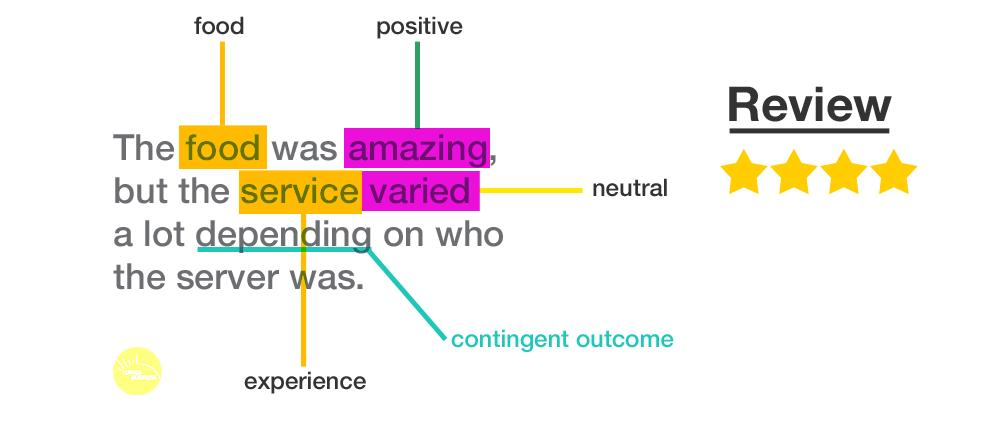
Example:

> “The food was delicious, but the service was painfully slow.”

| Aspect  | Sentiment |
| ------- | --------- |
| Food    | Positive  |
| Service | Negative  |

A single overall label would lose this important distinction.

Industry use: Finding which product features customers like or dislike, instead of merely calculating an overall sentiment score.

## 3. Sentiment analysis workflow

The workflow in your video runs from data collection through model evaluation.

#### 1

### Data collection

Reviews, social media posts, feedback

#### 2

### Preprocessing

Clean and prepare text appropriately

#### 3

### Representation

TF-IDF, embeddings or tokenizer IDs

#### 4

### Model training

Learn sentiment patterns from labeled examples

#### 5

### Evaluation

Measure performance on unseen data

### Step 1 — Data collection

Obtain text from sources such as product reviews, customer surveys, social media or support tickets.

### Step 2 — Preprocessing

Depending on the model, preprocessing may include HTML removal, Unicode handling, whitespace normalization and text validation.

Do not automatically remove negation words such as not or never. Also, pretrained Transformer models usually require their own tokenizer and should not receive aggressively stemmed or stripped text by default.

### Step 3 — Representation

Convert text into a form the model can process.

- Classical ML: TF-IDF vectors.
- Neural models: learned or pretrained embeddings.
- Transformers: tokenizer-generated token IDs and attention masks.

### Step 4 — Model training

Train a classifier using labeled examples, or fine-tune a pretrained model for the task.

### Step 5 — Evaluation

Evaluate using a held-out test set. Accuracy alone can be misleading if one sentiment class dominates the dataset.

## 4. Approaches to sentiment analysis

Your video introduces three main approaches: rule-based methods, classical machine learning, and deep learning.

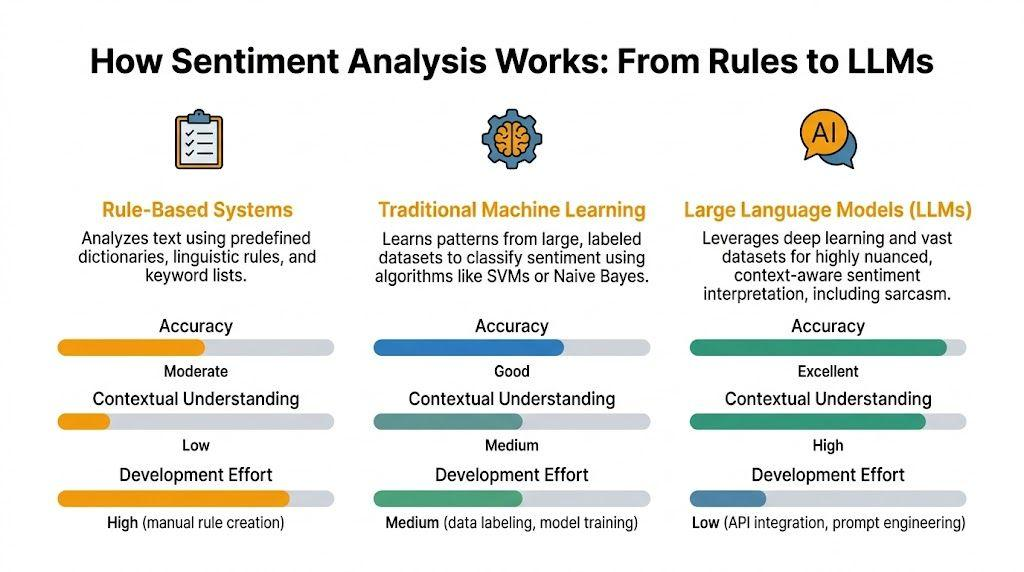

### 4.1 Rule-based approach — VADER

VADER (Valence Aware Dictionary and sEntiment Reasoner) uses a sentiment lexicon and rules to estimate sentiment. It is designed particularly for social-media-style text.

Example:

```
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzeranalyzer = SentimentIntensityAnalyzer()text = "The product is absolutely amazing!"scores = analyzer.polarity_scores(text)print(scores)
```

The result contains `neg`, `neu`, `pos` and `compound` scores. The compound score summarizes sentiment on a scale from −1 to +1; standard VADER thresholds can map it to negative, neutral or positive.

Advantages: Fast, interpretable and does not require task-specific training data.

Limitations: Can struggle with domain-specific meanings, subtle context and sarcasm.

### 4.2 Classical machine learning



A classical pipeline typically looks like this:

```
Labeled reviews
      ↓
Text preprocessing
      ↓
TF-IDF features
      ↓
Classifier
      ↓
Sentiment prediction
```

Common algorithms:

- Naive Bayes: A fast probabilistic baseline.
- Logistic Regression: A strong baseline for sparse text features.
- Linear SVM: Often effective for high-dimensional TF-IDF representations.

For your syllabus, TF-IDF + Logistic Regression is a sensible first baseline. We will compare it with other models during Module 14.

### 4.3 Deep learning

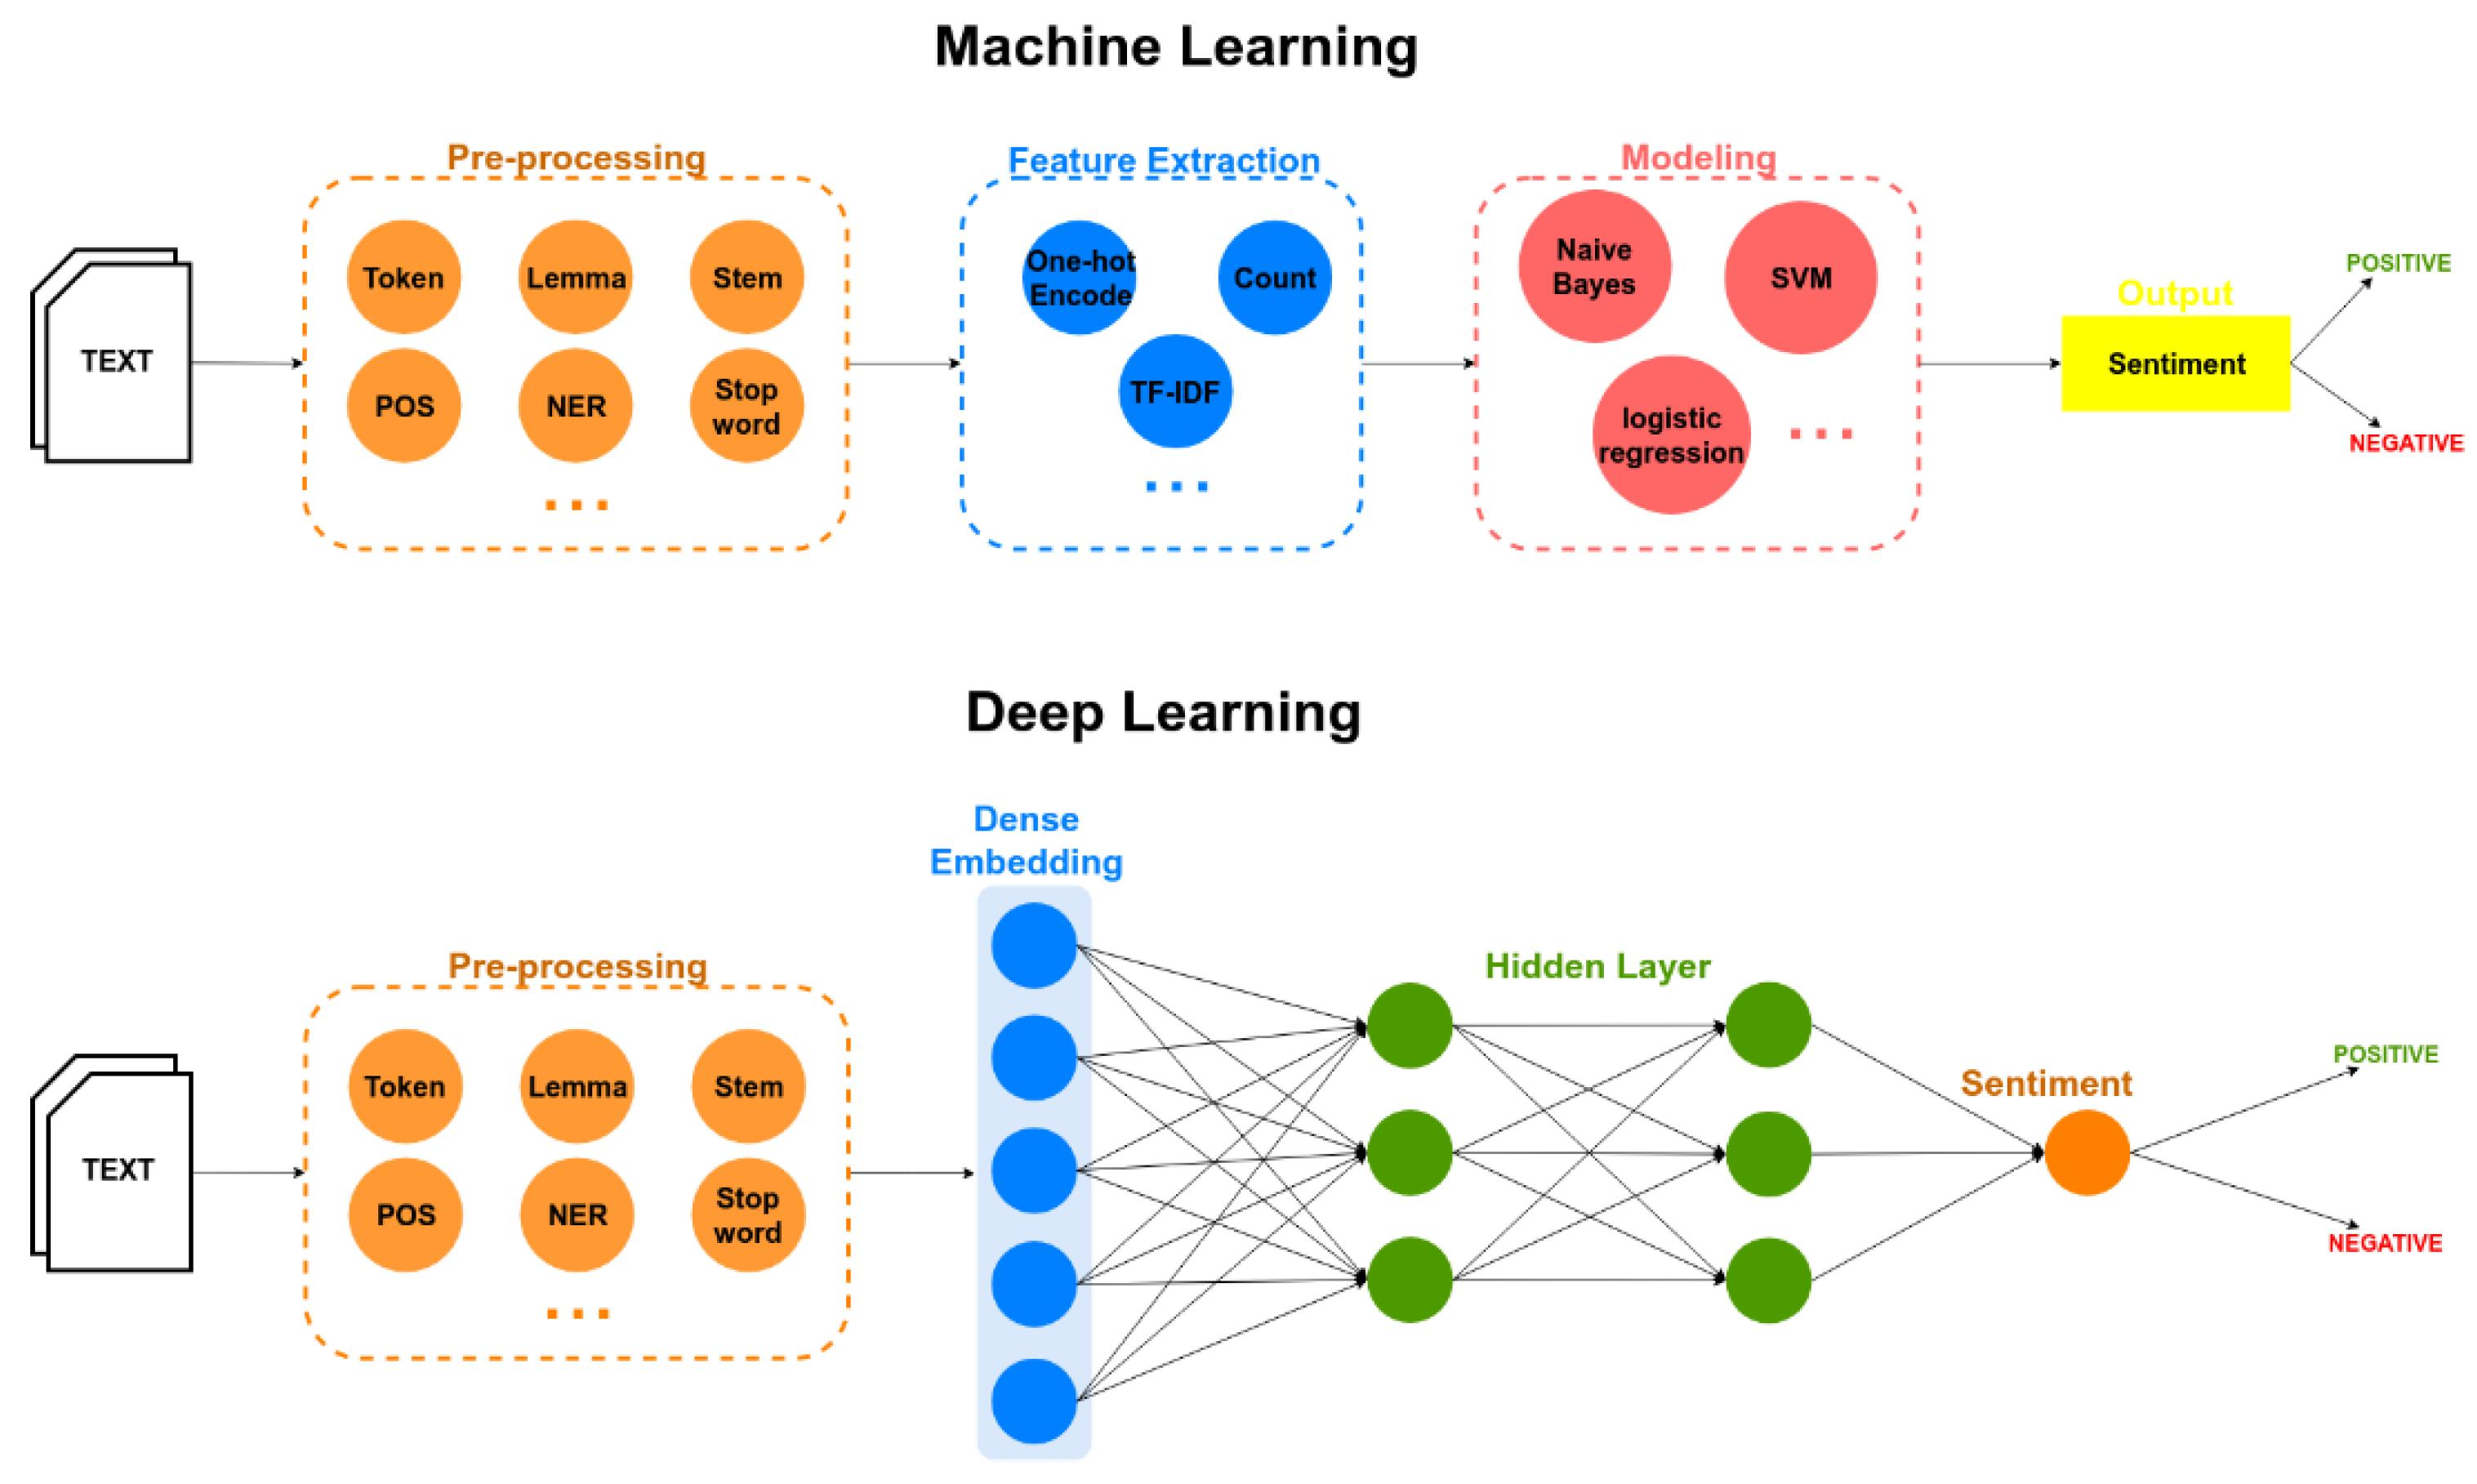

Deep learning models can learn richer representations of language.

| Model            | Main idea                                                                                    |
| ---------------- | -------------------------------------------------------------------------------------------- |
| RNN              | Processes tokens sequentially                                                                |
| LSTM / GRU       | Models sequential information with gated recurrent units                                     |
| BERT             | Produces bidirectional contextual representations                                            |
| GPT-style models | Use causal language modeling; can also perform sentiment tasks when appropriately configured |

BERT is commonly fine-tuned with a classification head for supervised sentiment classification. Since you already know RNN, LSTM, GRU and basic Transformer concepts, focus on how text is represented, how the classifier is trained, and how the approaches compare.

## 5. Challenges in sentiment analysis

| Challenge         | Example                               | Why it is difficult                            |
| ----------------- | ------------------------------------- | ---------------------------------------------- |
| Sarcasm           | “Fantastic! Another two-hour delay.”  | Literal words conflict with intended sentiment |
| Negation          | “The movie was not good.”             | Negation changes polarity                      |
| Ambiguity         | “The plot is unpredictable.”          | Could be praise or criticism                   |
| Domain dependency | “That phone is sick.”                 | Slang meaning depends on context               |
| Mixed sentiment   | “Great screen, poor battery.”         | Different aspects have different polarity      |
| Data sparsity     | Rare words or specialized terms       | Training data may not cover them adequately    |
| Class imbalance   | 90% positive, 5% negative, 5% neutral | A model can favor the majority class           |

The central challenge is that sentiment is contextual. Recognizing a positive word is not enough to understand the opinion being expressed.

## 6. Improving sentiment model performance

Your video discusses four important areas: class imbalance, data augmentation, feature engineering and pretrained models.

### 6.1 Handling class imbalance

Suppose a dataset contains 9,000 positive reviews, 500 negative reviews and 500 neutral reviews. A model could achieve 90% accuracy by predicting positive for every review, yet fail to detect the other classes.

Common techniques:

- Undersampling: Reduce examples from the majority class. It is simple but can discard useful data.
- Oversampling: Increase representation of minority classes, for example by duplicating minority examples.
- Class-weighted loss: Penalize errors on underrepresented classes more heavily.
- SMOTE: Creates synthetic minority examples by interpolating between feature vectors. It is primarily designed for numerical feature spaces; applying it directly to raw text or TF-IDF vectors requires care, because synthetic vectors may not correspond to valid text.

For neural models, class-weighted loss is often a reasonable starting point. Always compare per-class precision, recall and F1-score.

### 6.2 Data augmentation

Data augmentation increases training diversity when labeled data is limited.

| Technique           | Example                                      | Caution                                |
| ------------------- | -------------------------------------------- | -------------------------------------- |
| Synonym replacement | “The movie was good” → “The movie was great” | Synonyms may change sentiment strength |
| Random insertion    | Insert a relevant word                       | Can create unnatural sentences         |
| Random deletion     | Remove a nonessential word                   | May remove negation or sentiment cues  |
| Back-translation    | English → another language → English         | Meaning or sentiment may change        |

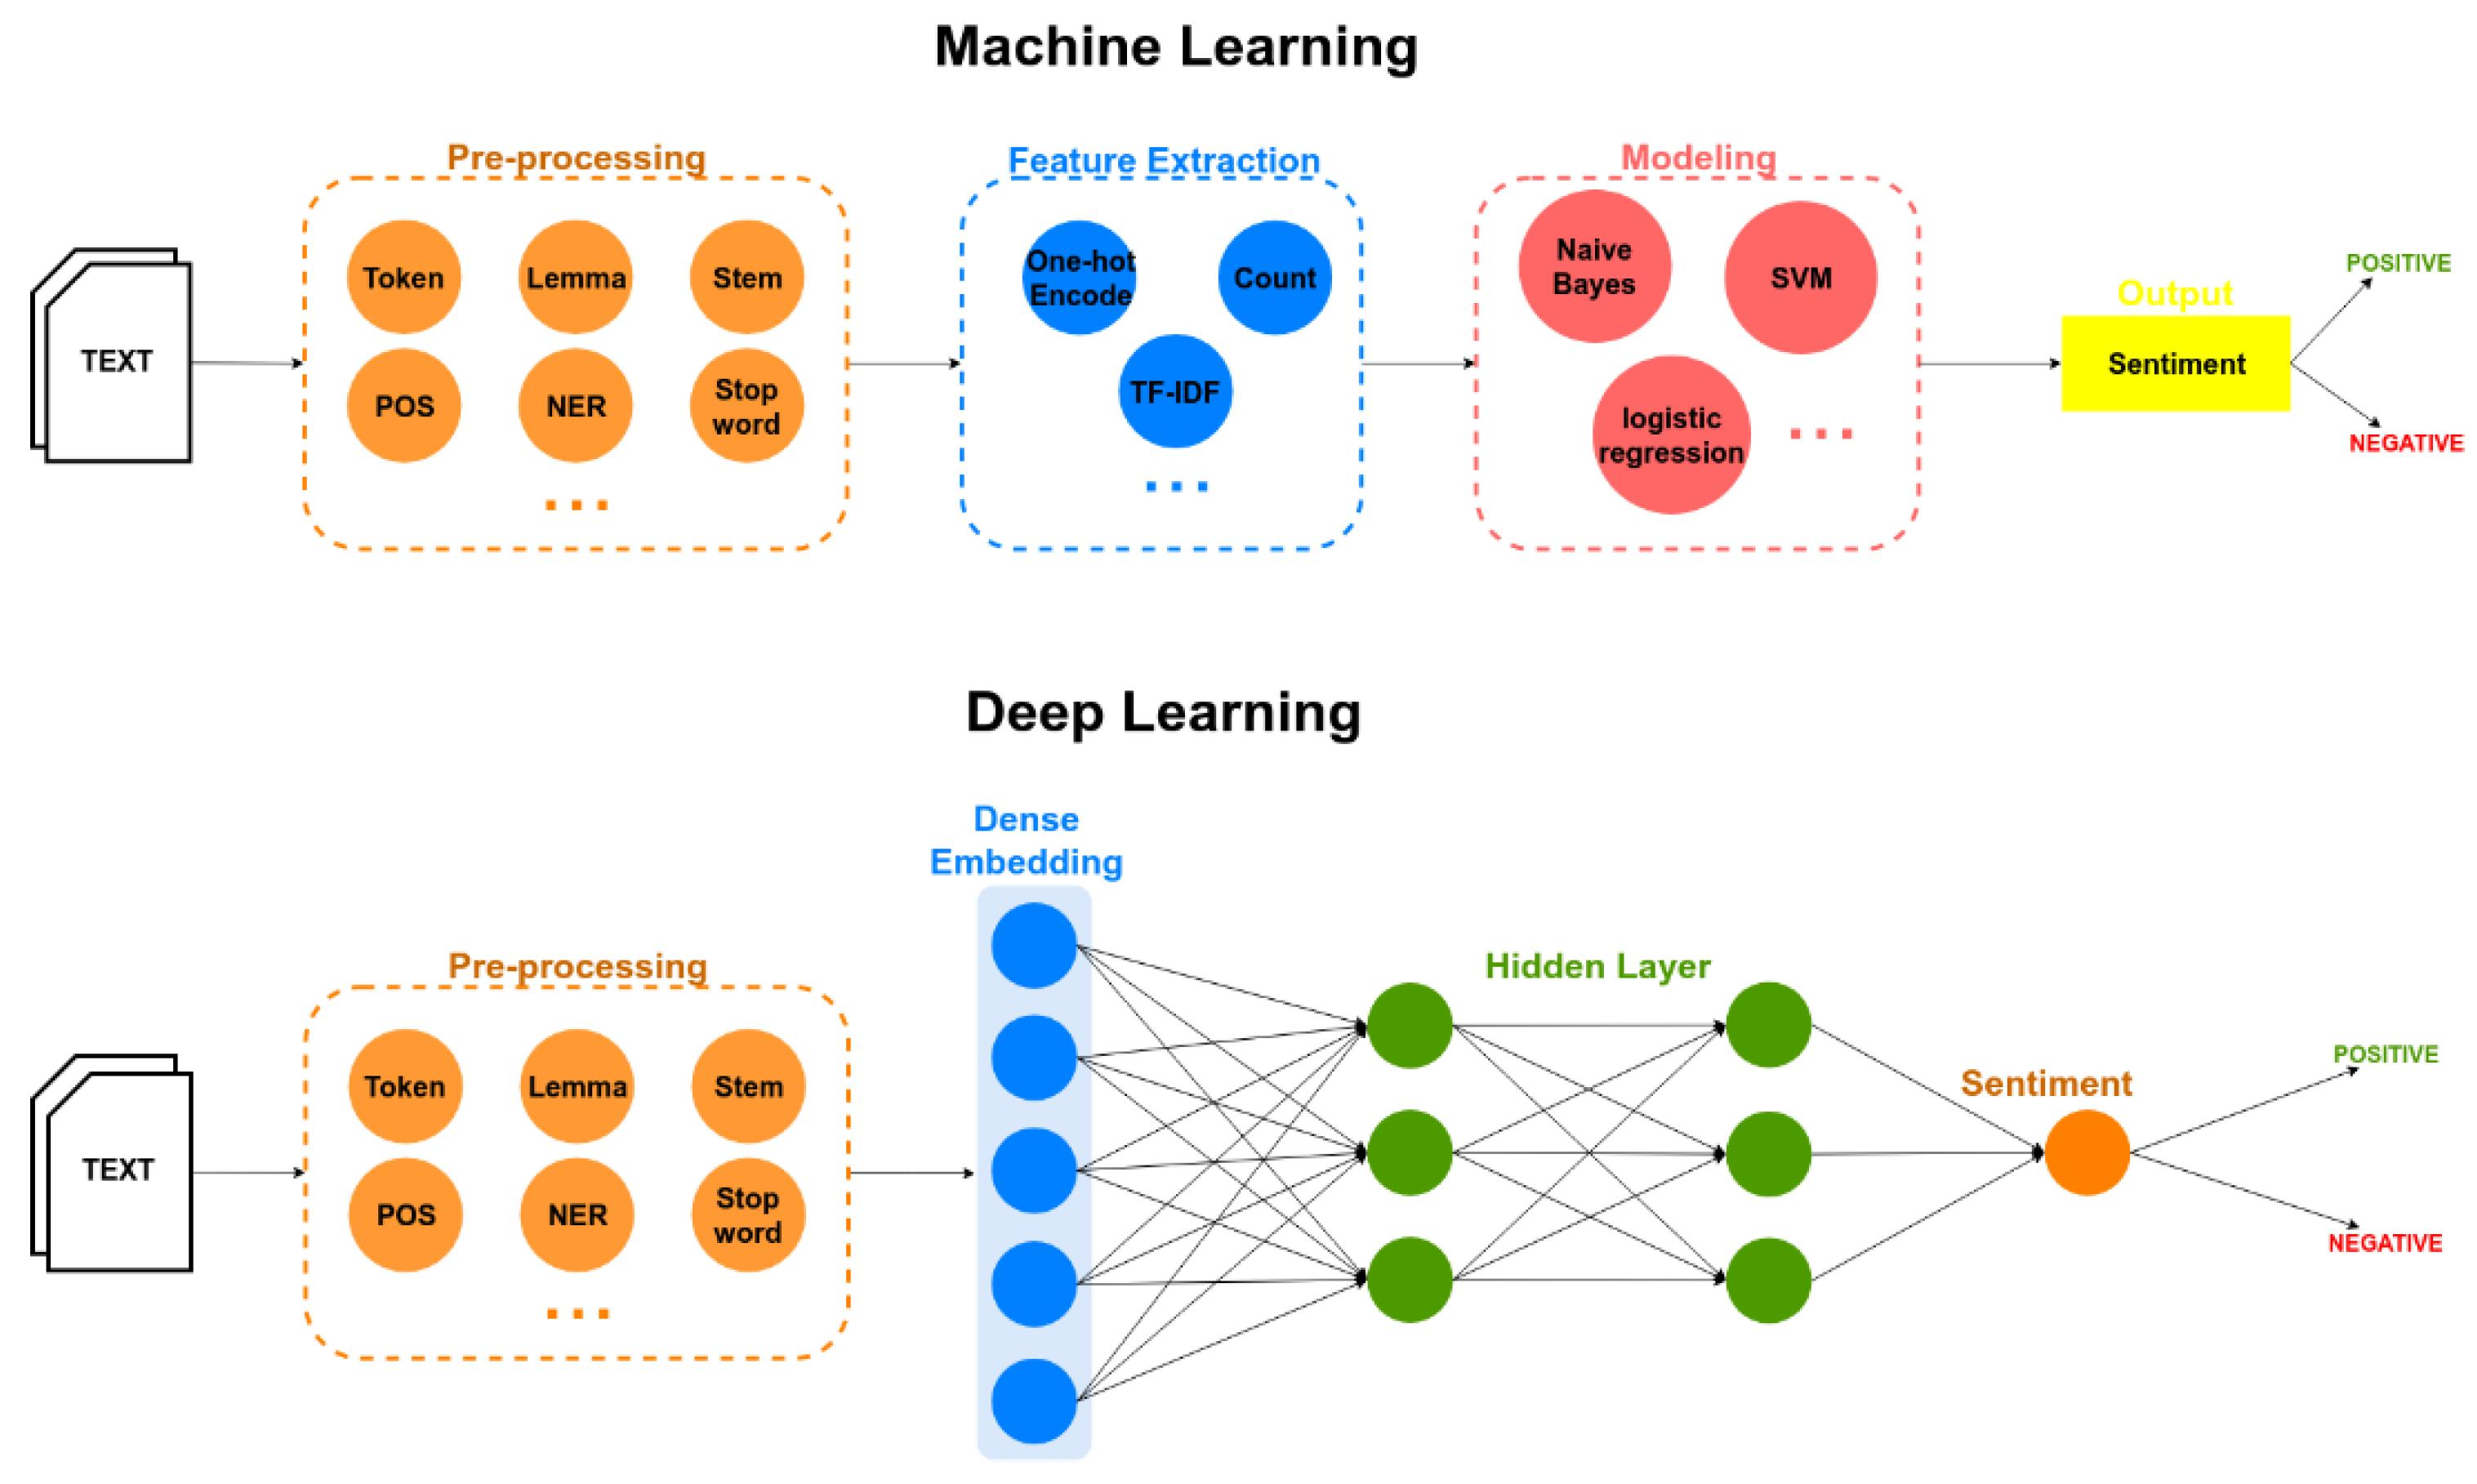

Important: Validate augmented examples before using them. For sentiment tasks, even a small change can reverse the label. Augment training data only, not the test set.

### 6.3 Feature engineering

Feature engineering determines what information the model receives.

- TF-IDF: Highlights informative terms; a strong classical baseline.
- Word2Vec: Learns static word representations from surrounding contexts.
- GloVe: Learns word representations using global co-occurrence statistics.
- BERT embeddings: Represent words in context and can capture different meanings depending on surrounding text.

For example, “cold” in “cold weather” and “cold customer service” may have different implications. Contextual representations can help distinguish them.

### 6.4 Pretrained models and fine-tuning



Pretrained models have already learned useful language patterns from large text corpora. Fine-tuning adapts a pretrained model to a labeled sentiment dataset.

A practical progression is:

1. Establish a VADER baseline when suitable.
2. Train TF-IDF + Logistic Regression.
3. Compare Naive Bayes and Linear SVM.
4. Fine-tune a pretrained Transformer such as BERT if the task justifies the additional compute.

One distinction: VADER is a rule-based analyzer, not a pretrained neural model that you fine-tune. GPT-style models can perform sentiment analysis through prompting or task-specific adaptation, but they are not automatically the best choice for every classification problem.

Since you have CUDA, we can use GPU acceleration for Transformer fine-tuning when appropriate, while keeping classical baselines lightweight.

## 7. Evaluation: how do we know the model improved?

Use a separate test set that is not used to choose model parameters.

| Metric           | What it tells you                                |
| ---------------- | ------------------------------------------------ |
| Accuracy         | Overall proportion of correct predictions        |
| Precision        | How many predictions for a class are correct     |
| Recall           | How many actual examples of a class are detected |
| F1-score         | Balance between precision and recall             |
| Confusion matrix | Which classes the model confuses                 |

For an imbalanced three-class sentiment dataset, macro F1-score is especially useful because it gives equal weight to each class's F1-score.

A more complex model is not automatically a better model. Compare it against the baseline on the same test data.

## 8. Video timestamps — revision guide

Use the timestamps you supplied to revisit each section.

| Time        | Topic                            |
| ----------- | -------------------------------- |
| 02:09–02:44 | Definition                       |
| 04:14–04:57 | Importance                       |
| 05:47–07:16 | Types of sentiment analysis      |
| 07:17–08:27 | Workflow                         |
| 08:28–10:33 | Rule-based, ML and DL approaches |
| 10:34–12:29 | Challenges                       |
| 12:30–15:11 | General performance improvements |
| 15:12–17:46 | Class imbalance                  |
| 17:47–19:43 | Data augmentation                |
| 19:44–20:43 | Feature engineering              |
| 20:47–22:10 | Pretrained models                |

These timestamps come from your supplied summary; I have not independently verified the video's contents against those time ranges.

## What you should remember

1. Sentiment analysis identifies polarity or opinions; emotion detection identifies more specific feelings.
2. Fine-grained analysis distinguishes sentiment intensity, while ABSA identifies sentiment toward individual aspects.
3. Rule-based, classical ML and deep learning approaches have different costs and capabilities.
4. Class imbalance, sarcasm, negation and domain dependency can cause significant errors.
5. Data augmentation and feature engineering must preserve sentiment meaning.
6. Pretrained Transformers can be fine-tuned for sentiment classification.
7. Use held-out evaluation and error analysis to establish whether an improvement is real.

---